# Рис. 5: Построение спектра троек по меткам ручной разметки

In [1]:
import os
import numpy as np
import pandas as pd
from pathlib2 import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from wavelet_analysis import morlet_power_matrix

### Инициализация путей и параметров

In [2]:
data_dir = Path(r"C:\Users\alvar\Documents\practice\test_repo_spectral_analysis")
triples_file = data_dir / "sum_edges_triples" / "native_manual_sum_edges_triples.npz"  # или .npy
triples_key = "sum_triples"          # ключ в npz; для .npy-файла не используется
markup_csv = data_dir / "markups" / "mk_labels_CA1_22_1D_alena.csv"
markup_column = "label"
n_frames = 18775

fs = 20.0                            # частота кадров, Гц
freqs = np.linspace(0.1, 10.0, 500) 
exclude_labels = [0]                 # 0 — «Не определено»
width_cm = 8                         # 8 см — полстраницы, 16 см — целая страница

path_to_save = data_dir / "figures" / "spectra"
out_file = path_to_save / "triple_spectrum_behavior.pdf"   # None — только показать в ноутбуке

In [3]:
style = {   # метка: (подпись, цвет, тип линии)
    4: ("Running",         "#3d5a80", "-"),
    3: ("Sitting",         "#e07a5f", "-"),
    2: ("Grooming",        "#6b8750", "-"),
    5: ("Looking outside", "#6d597a", "-"),
    7: ("Rearing outside", "#f2cc8f", "-"),
    6: ("Looking inside",  "#b56576", "-"),
    8: ("Rearing inside",  "#2a9d8f", "-"),
}
# ---------------------------------------------------------------------

CM = 1 / 2.54
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "pdf.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
})

### Загрузка и обработка данных

In [4]:
if triples_file.suffix == ".npy":
    triples = np.load(triples_file)
else:
    with np.load(triples_file) as z:
        triples = z[triples_key]
labels = pd.read_csv(markup_csv)[markup_column].to_numpy()
n = min(n_frames, len(triples), len(labels))
triples, labels = triples[:n], labels[:n]

power = morlet_power_matrix(triples, freqs)          # вейвлет считается по всему ряду,
                                              # усреднение — по кадрам каждой метки

### Построение кривых

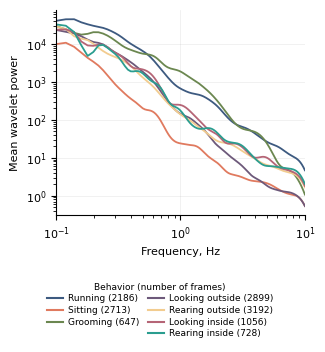

In [5]:
fig = plt.figure(figsize=(width_cm * CM, 9.0 * CM))
ax = fig.add_axes([0.17, 0.37, 0.79, 0.58])   # место под легенду оставлено внизу

handles = []
for lab, (name, color, ls) in style.items():
    if lab in exclude_labels:
        continue
    idx = np.where(labels == lab)[0]
    if len(idx) == 0:
        print(f"Метка {lab} ({name}) не встречается в разметке — пропускаю")
        continue
    line, = ax.plot(freqs, power[:, idx].mean(axis=1), color=color, ls=ls, lw=1.3)
    handles.append(Line2D([], [], color=color, ls=ls, lw=1.5,
                          label=f"{name} ({len(idx)})"))

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(freqs.min(), freqs.max())
ax.set_xlabel("Frequency, Hz")
ax.set_ylabel("Mean wavelet power")
ax.grid(True, which="major", alpha=0.25, lw=0.5)

# колонки легенды: слева — бег/покой/умывание, справа — взгляды и стойки
n_left = sum(1 for lab in (4, 3, 2) if lab not in exclude_labels and np.any(labels == lab))
handles = handles[:n_left] + [Line2D([], [], alpha=0, label=" ")] + handles[n_left:]

# компактная легенда под графиком на всю ширину рисунка, 2 колонки; в скобках — число кадров метки
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=2,
           frameon=False, fontsize=6.5, handlelength=1.8, handletextpad=0.5,
           columnspacing=1.0, labelspacing=0.3,
           title="Behavior (number of frames)", title_fontsize=6.5)

if out_file:
    fig.savefig(out_file)
    fig.savefig(out_file.with_suffix(".png"), dpi=300)
plt.show()